In [5]:
import sys
sys.dont_write_bytecode = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.options.display.float_format = "{:.2f}".format

In [11]:
df = pd.DataFrame()
df["Encoder_Decoder"] = ["FP16", 141185, 24, 64.16, 8218.03, 90.65, 0.82]
df["Encoder_Decoder_AF"] = ["FP32", 144257, 28, 59.64, 8250.06, 90.83, 0.82]
df["Attention"] = ["FP32", 595969, 40, 46.17, 4763.72, 69.02, 0.90]
df["Attention_AF"] = ["FP32", 596737, 40, 44.82, 4486.02, 66.98, 0.90]
df.index = ["Precision", "Params", "Epochs", "MAE", "MSE", "RMSE", "R2"]
dft =df.T

display(df)
display(dft)

,Encoder_Decoder,Encoder_Decoder_AF,Attention,Attention_AF
Precision,FP16,FP32,FP32,FP32
Params,141185,144257,595969,596737
Epochs,24,28,40,40
MAE,64.16,59.64,46.17,44.82
MSE,8218.03,8250.06,4763.72,4486.02
RMSE,90.65,90.83,69.02,66.98
R2,0.82,0.82,0.90,0.90


,Precision,Params,Epochs,MAE,MSE,RMSE,R2
Encoder_Decoder,FP16,141185,24,64.16,8218.03,90.65,0.82
Encoder_Decoder_AF,FP32,144257,28,59.64,8250.06,90.83,0.82
Attention,FP32,595969,40,46.17,4763.72,69.02,0.90
Attention_AF,FP32,596737,40,44.82,4486.02,66.98,0.90


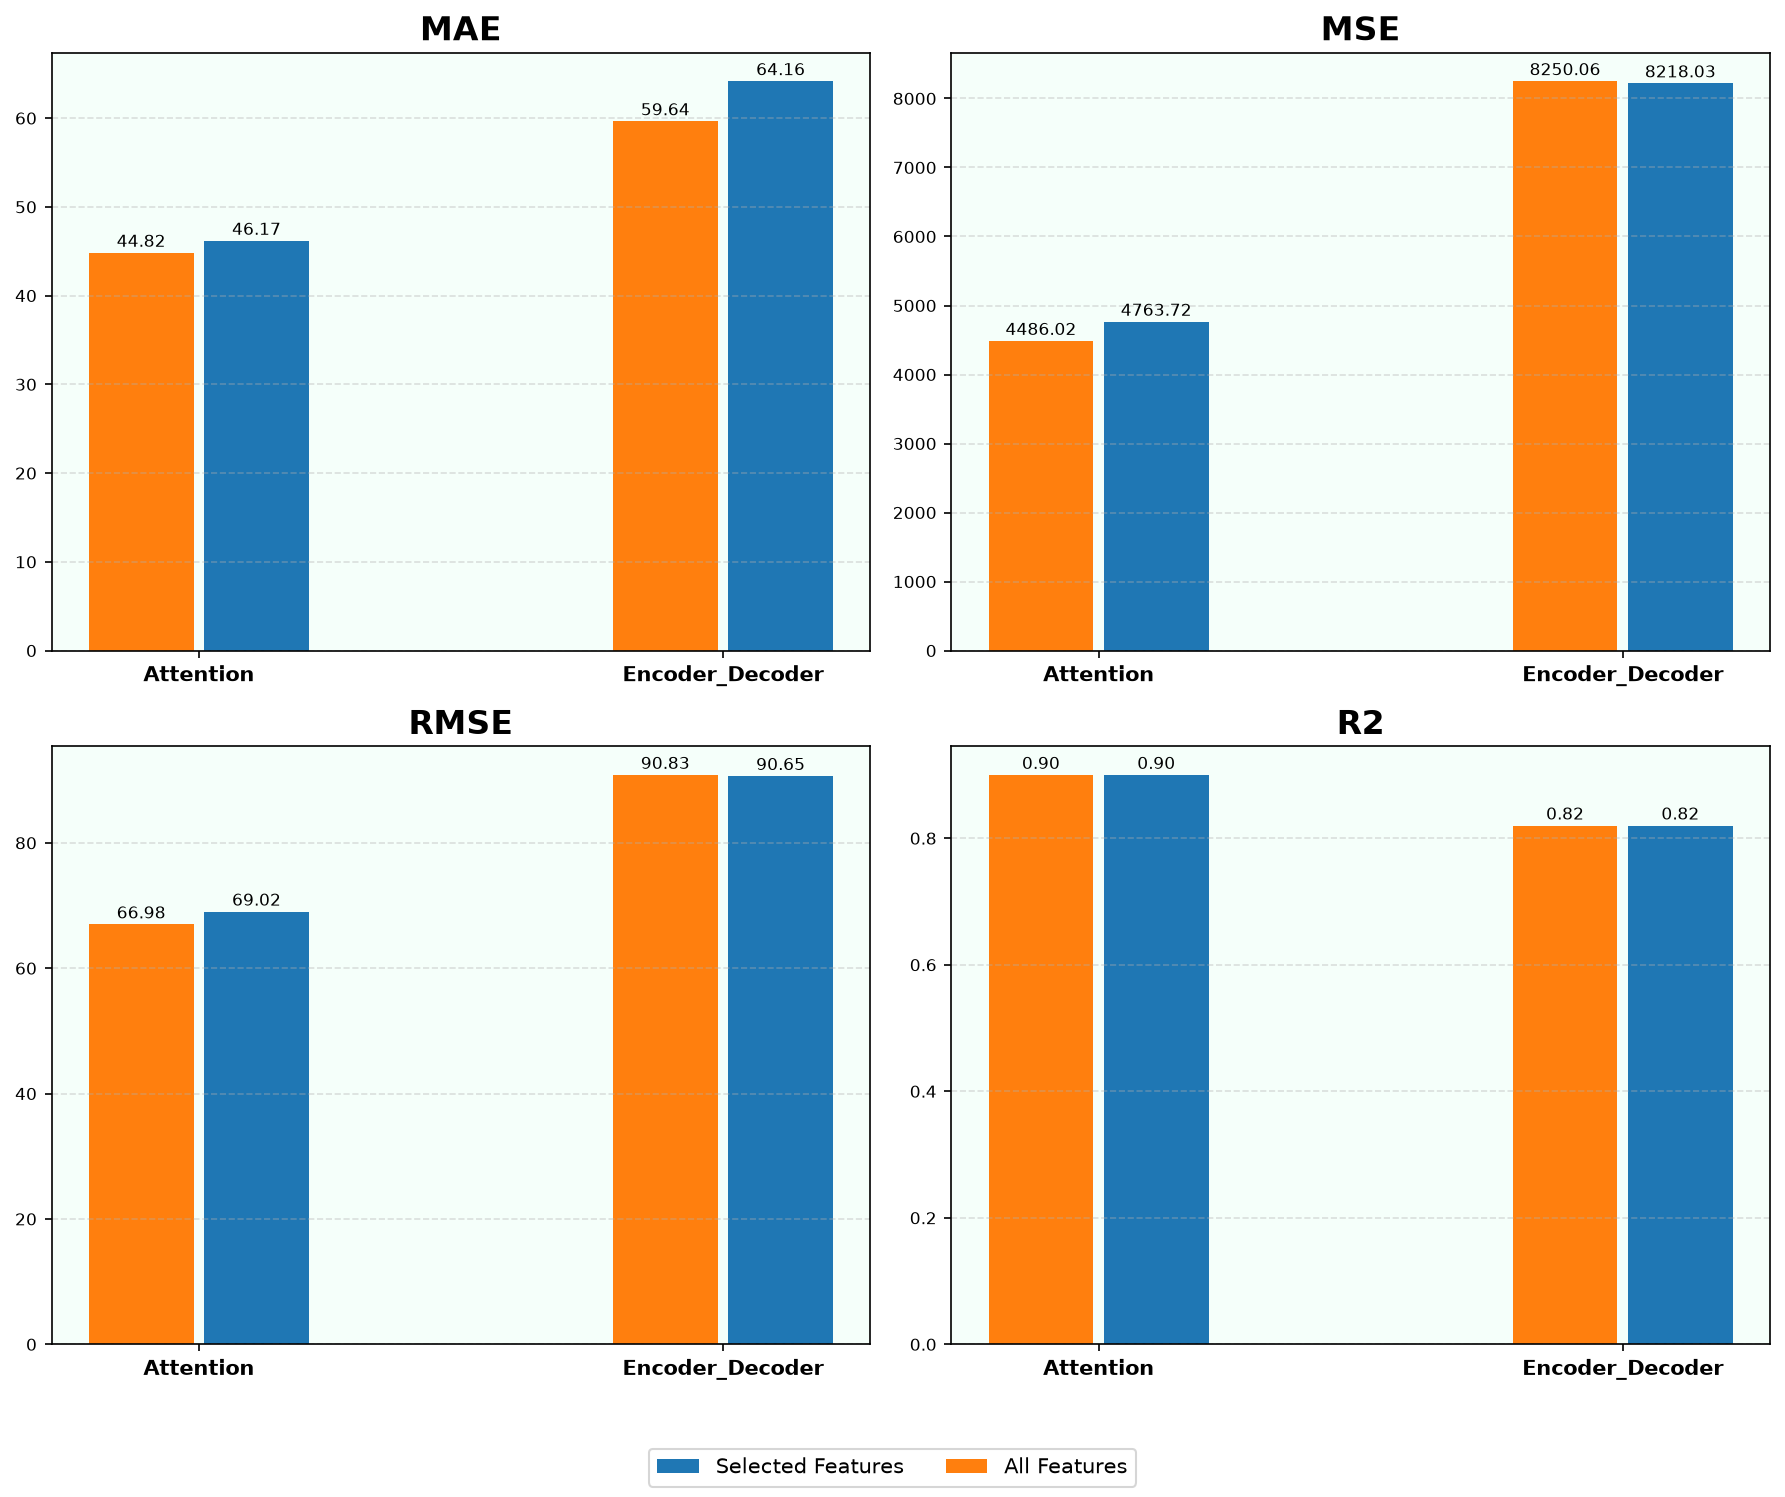

In [80]:
metrics = ["MAE", "MSE", "RMSE", "R2"]

groups = {
    "Encoder_Decoder": ("Encoder_Decoder", "Encoder_Decoder_AF"),
    "Attention": ("Attention", "Attention_AF"),
}

colors = {"non-AF": "tab:blue", "AF": "tab:orange"}
height = 0.2
y = np.arange(len(groups))

fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=150)

for ax, metric in zip(axes.flat, metrics):
      non_af = [float(df.loc[metric, pair[0]]) for pair in groups.values()]
      af = [float(df.loc[metric, pair[1]]) for pair in groups.values()]

      bars_non_af = ax.bar(y-0.11, non_af, height, label="Selected Features", color=colors["non-AF"])
      bars_af = ax.bar(y+0.11, af, height, label="All Features", color=colors["AF"])

      # values at the end of each bar
      ax.bar_label(bars_non_af, fmt="%.2f", padding=1, size=8)
      ax.bar_label(bars_af, fmt="%.2f", padding=1, size=8)

      ax.set_xticks(y, labels=list(groups.keys()), size=10, fontweight='bold')
      ax.tick_params(axis='y', labelsize=8)
      ax.invert_xaxis()                    # first category on top
      ax.set_title(metric, fontweight="bold", size=16)
      #ax.margins(x=0.15)
      ax.set_facecolor('#F5FFFA')
      ax.grid(axis="y", linestyle="--", alpha=0.4)



# one shared legend instead of four identical ones
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True)

fig.tight_layout(rect=[0, 0.06, 1, 1])   # leave space at bottom for legend
plt.show()